# Bab 5 — Linear Models and Regularization

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025)

---

| No | Resep | Kelas scikit-learn | Ide utama |
|----|-------|--------------------|-----------|
| 1 | Pengantar model linear | `LinearRegression` | OLS: minimalkan jumlah kuadrat galat |
| 2 | Ridge & Lasso | `Ridge`, `Lasso` | penalti L2 (mengecilkan) dan L1 (menolkan) koefisien |
| 3 | ElasticNet | `ElasticNet` | kombinasi L1 + L2; *coefficient path* |
| 4 | Regresi polinomial & spline | `PolynomialFeatures`, `SplineTransformer` | basis non-linear + model linear |
| 5 | Latihan | Ridge, Lasso, ElasticNet pada data sintetis | |


## Resep 1 — Pengantar Model Linear

### Teori
Regresi linear memodelkan target sebagai kombinasi linear fitur:
$$y = \beta_0 + \beta_1x_1 + \dots + \beta_px_p + \varepsilon = \mathbf{x}^\top\boldsymbol\beta + \varepsilon$$

**Ordinary Least Squares (OLS)** memilih $\boldsymbol\beta$ yang meminimalkan *residual sum of squares*:
$$\hat{\boldsymbol\beta}_{\text{OLS}} = \arg\min_{\boldsymbol\beta}\; \lVert\mathbf{y} - \mathbf{X}\boldsymbol\beta\rVert_2^2 = (\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{y}$$

Asumsi klasik (Gauss–Markov): hubungan linear, galat bermean nol dan independen, varians galat konstan (homoskedastis), serta tidak ada multikolinearitas sempurna. Di bawah asumsi ini OLS adalah estimator linear tak bias dengan varians terkecil (**BLUE**).

**Masalah multikolinearitas:** jika beberapa fitur hampir identik, $\mathbf{X}^\top\mathbf{X}$ hampir singular (nilai eigennya ada yang mendekati 0), sehingga inversnya sangat besar. Akibatnya varians koefisien,
$$\operatorname{Var}(\hat{\boldsymbol\beta}) = \sigma^2(\mathbf{X}^\top\mathbf{X})^{-1},$$
membengkak: koefisien jadi tidak stabil, bisa sangat besar dengan tanda berlawanan, dan sulit diinterpretasikan.

**Metrik evaluasi:**
- $\text{MSE} = \frac{1}{n}\sum_i (y_i-\hat y_i)^2$ — dalam satuan kuadrat target.
- $R^2 = 1 - \frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}$ — proporsi variasi target yang dijelaskan model (1 = sempurna, 0 = setara memprediksi rata-rata, bisa negatif pada data uji).

### Persiapan — dataset sintetis dengan multikolinearitas

In [ ]:
# Kode buku memicu banyak UserWarning tentang nama fitur (model dilatih dengan array NumPy
# lalu diprediksi dengan DataFrame). Peringatan ini tidak memengaruhi hasil, jadi disembunyikan.
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

# Kode buku menambahkan noise dengan np.random.normal tanpa seed, sehingga hasil berubah
# setiap kali dijalankan. Seed global diset di sini agar notebook reproducible.
import numpy as np
np.random.seed(123)

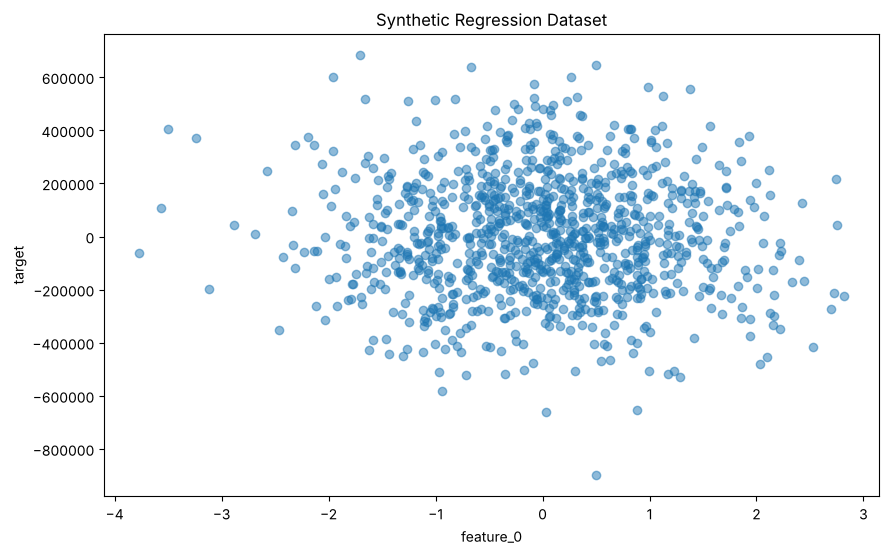

In [ ]:
# Load libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression

# Create synthetic regression dataset with high multicollinearity and more features
X, y = make_regression(n_samples=1000,
                      n_features=100,
                      n_informative=10,
                      noise=20,
                      random_state=123)

# Add multicollinearity by creating correlated features
for i in range(50, 100):  # Make half the features correlated
    X[:, i] = X[:, i-50] + np.random.normal(0, 0.1, size=1000)

# Create feature names
feature_names = [f'feature_{i}' for i in range(100)]

# Take just the first feature for visualization
X_plot = X[:, 0].reshape(-1, 1)

# Add some non-linearity and make coefficients vary widely in magnitude
y = y * 1000  # Scale up the target
y = y + np.sin(X_plot.ravel()) * 150 + np.exp(X_plot.ravel()/10)

# Convert to pandas DataFrame with feature names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y
df_plot = pd.DataFrame({'feature_0': X_plot.ravel(), 'target': y})

# Quick visualization of the data
plt.figure(figsize=(10, 6))
plt.scatter(X_plot, y, alpha=0.5)
plt.xlabel('feature_0')
plt.ylabel('target')
plt.title('Synthetic Regression Dataset')
plt.show()

Mean Squared Error: 46550591070.53
R-squared: 0.06


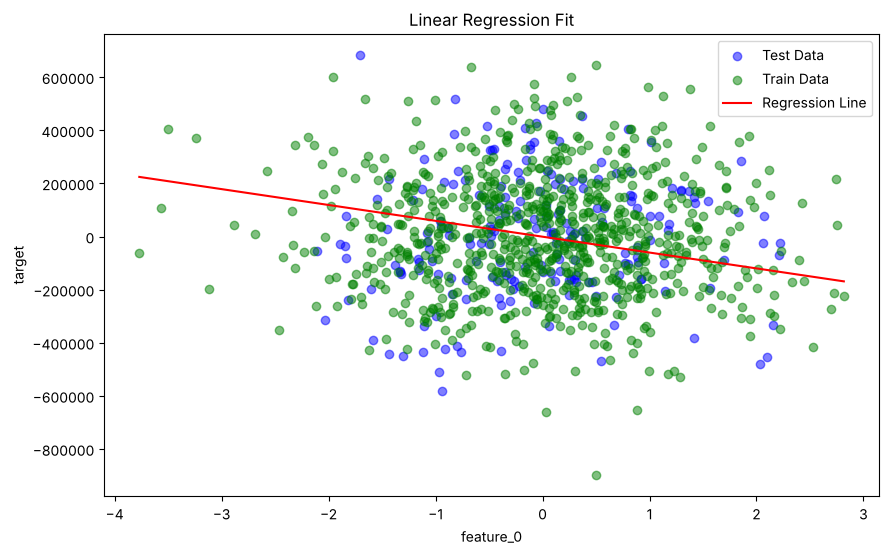

In [ ]:
# Load libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

# Create and fit Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = linear_model.predict(X_test)

# Evaluate performance using MSE and R-squared
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f'Mean Squared Error: {mse:.2f}')
print(f'R-squared: {r2:.2f}')

# Visualize the data and regression line (using feature_0 for visualization)
plt.figure(figsize=(10, 6))
plt.scatter(X_test[:, 0], y_test, color='blue', alpha=0.5, label='Test Data')
plt.scatter(X_train[:, 0], y_train, color='green', alpha=0.5, label='Train Data')

# Sort the data for a smooth line plot
X_line = np.linspace(df['feature_0'].min(), df['feature_0'].max(), 100).reshape(-1, 1)
X_line_full = np.zeros((100, len(feature_names)))
X_line_full[:, 0] = X_line.ravel()  # Set feature_0, leave others as 0
y_line = linear_model.predict(pd.DataFrame(X_line_full, columns=feature_names))

plt.plot(X_line, y_line, color='red', label='Regression Line')
plt.xlabel('feature_0')
plt.ylabel('target')
plt.title('Linear Regression Fit')
plt.legend()
plt.show()

In [ ]:
# Diagnostik multikolinearitas: condition number dari X^T X
XtX = X_train.T @ X_train
eig = np.linalg.eigvalsh(XtX)
print('Eigenvalue terkecil X^T X : %.4f' % eig.min())
print('Eigenvalue terbesar X^T X : %.1f' % eig.max())
print('Condition number          : %.0f' % (eig.max() / eig.min()))

# Korelasi fitur_0 dengan pasangannya fitur_50
print('Korelasi feature_0 vs feature_50: %.4f' % np.corrcoef(X[:, 0], X[:, 50])[0, 1])

Eigenvalue terkecil X^T X : 2.0884
Eigenvalue terbesar X^T X : 2484.9
Condition number          : 1190
Korelasi feature_0 vs feature_50: 0.9952


**Interpretasi — mengapa $R^2$ hanya ≈ 0,06?**

Diagnostik di atas mengonfirmasi multikolinearitas yang ekstrem: `feature_0` dan `feature_50` berkorelasi 0,995, dan *condition number* $\mathbf X^\top\mathbf X$ ribuan kali lebih besar daripada data yang tidak berkorelasi. Namun multikolinearitas **bukan** satu-satunya penyebab $R^2$ yang sangat rendah. Penyebab utamanya ada pada cara dataset dibuat, yang bisa kita telusuri di sel berikut.

`make_regression` mengacak posisi 10 fitur informatif. Setelah itu, kode buku **menimpa** kolom 50–99 dengan salinan kolom 0–49. Jika fitur informatif kebetulan berada di kolom 50–99, nilai aslinya yang menentukan $y$ hilang, sehingga sebagian besar variasi target tidak lagi dapat dijelaskan oleh fitur apa pun.

In [ ]:
# Telusuri: fitur mana yang sebenarnya informatif? (coef=True mengembalikan koefisien sebenarnya)
_, _, true_coef = make_regression(n_samples=1000, n_features=100, n_informative=10,
                                  noise=20, random_state=123, coef=True)
info_idx = np.nonzero(true_coef)[0]
print('Indeks fitur informatif :', info_idx)
print('Yang ditimpa (indeks >= 50):', info_idx[info_idx >= 50])

# Batas atas R^2 yang masih mungkin: porsi varians sinyal dari fitur informatif yang masih utuh
kept = info_idx[info_idx < 50]
share = (true_coef[kept] ** 2).sum() / (true_coef[info_idx] ** 2).sum()
print('Porsi varians sinyal yang masih tersedia: %.1f%%' % (100 * share))

Indeks fitur informatif : [ 3 21 25 66 68 71 75 81 98 99]
Yang ditimpa (indeks >= 50): [66 68 71 75 81 98 99]
Porsi varians sinyal yang masih tersedia: 21.5%


**Interpretasi.** Tujuh dari sepuluh fitur informatif berada di kolom 66, 68, 71, 75, 81, 98, dan 99 — semuanya tertimpa. Hanya fitur 3, 21, dan 25 yang tersisa, dan ketiganya hanya menyumbang sekitar 21% varians sinyal. Jadi bahkan model sempurna pun tidak akan mendapat $R^2$ jauh di atas ≈0,2 pada dataset ini. Sisa variasi target secara efektif menjadi "noise" yang tidak bisa diprediksi.

Dalam kondisi ini OLS dengan 100 fitur ikut "mencocokkan" noise tersebut (overfitting), sehingga $R^2$ uji hanya ≈0,06. MSE bernilai sangat besar (orde $10^{10}$) karena target dikalikan 1000, sehingga MSE ikut membesar $10^6$ kali — bandingkan model dengan $R^2$ atau dengan MSE relatif, bukan dari besar angkanya.

Garis merah pada plot adalah prediksi model ketika hanya `feature_0` yang divariasikan dan semua fitur lain bernilai 0 — sebuah irisan satu dimensi dari model 100 dimensi.

## Resep 2 — Ridge dan Lasso Regression

### Teori
Regularisasi menambahkan **penalti** pada ukuran koefisien ke fungsi objektif, sehingga model "dipaksa" sederhana.

**Ridge (penalti L2, Hoerl & Kennard 1970):**
$$\hat{\boldsymbol\beta}_{\text{ridge}} = \arg\min_{\boldsymbol\beta}\; \lVert\mathbf y - \mathbf X\boldsymbol\beta\rVert_2^2 + \alpha\lVert\boldsymbol\beta\rVert_2^2 = (\mathbf{X}^\top\mathbf{X} + \alpha\mathbf{I})^{-1}\mathbf{X}^\top\mathbf{y}$$
Menambahkan $\alpha\mathbf I$ menggeser setiap nilai eigen dari $\lambda_j$ menjadi $\lambda_j+\alpha$, sehingga matriks selalu dapat diinvers dan stabil. Ridge **mengecilkan** semua koefisien menuju nol, tetapi tidak pernah tepat nol. Pada fitur yang berkorelasi, Ridge cenderung **membagi** bobot secara merata di antara fitur-fitur tersebut.

**Lasso (penalti L1, Tibshirani 1996):**
$$\hat{\boldsymbol\beta}_{\text{lasso}} = \arg\min_{\boldsymbol\beta}\; \frac{1}{2n}\lVert\mathbf y - \mathbf X\boldsymbol\beta\rVert_2^2 + \alpha\lVert\boldsymbol\beta\rVert_1$$
Tidak ada solusi bentuk tertutup; scikit-learn memakai *coordinate descent*. Karena penalti L1 tidak mulus di titik nol, banyak koefisien menjadi **tepat nol** → Lasso sekaligus melakukan **seleksi fitur**. Pada fitur berkorelasi, Lasso cenderung memilih **salah satu** saja.

**Interpretasi geometris:** meminimalkan galat dengan kendala $\lVert\boldsymbol\beta\rVert_2 \le t$ (lingkaran) atau $\lVert\boldsymbol\beta\rVert_1 \le t$ (belah ketupat). Kontur galat paling sering menyentuh belah ketupat tepat di **sudutnya**, yaitu titik di mana sebagian koefisien bernilai nol.

**Bias–variance:** $\alpha$ besar → bias naik, varians turun. $\alpha = 0$ → kembali ke OLS.

Catatan: perhatikan bahwa skala $\alpha$ pada `Ridge` dan `Lasso` di scikit-learn berbeda (Lasso membagi galat dengan $2n$), sehingga nilai $\alpha$ keduanya tidak bisa dibandingkan langsung.

,Model,Mean Squared Error,R-squared
0,Ridge Regression,45341091794.40,0.09
1,Lasso Regression,46377111017.93,0.07
2,Linear Regression,46550591070.53,0.06


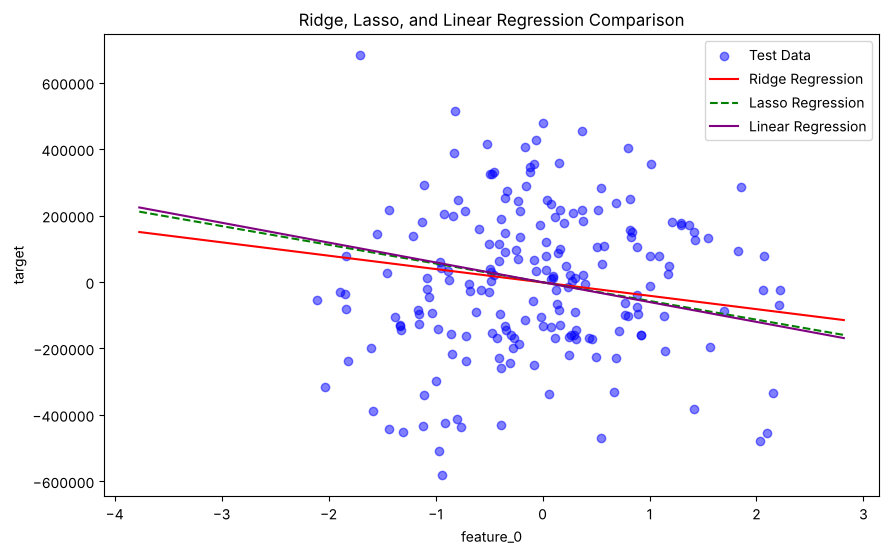

In [ ]:
# Load libraries
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

# Create and fit Ridge regression model
ridge_model = Ridge(alpha=1.0)  # alpha controls regularization strength
ridge_model.fit(X_train, y_train)

# Create and fit Lasso regression model with increased iterations and alpha
lasso_model = Lasso(alpha=10.0, max_iter=10000, tol=0.001)
lasso_model.fit(X_train, y_train)

# Make predictions with both models
y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)

# Evaluate performance
y_pred_linear = linear_model.predict(X_test)

# Calculate metrics for all models
metrics = {
    'Model': ['Ridge Regression', 'Lasso Regression', 'Linear Regression'],
    'Mean Squared Error': [
        mean_squared_error(y_test, y_pred_ridge),
        mean_squared_error(y_test, y_pred_lasso),
        mean_squared_error(y_test, y_pred_linear)
    ],
    'R-squared': [
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso),
        r2_score(y_test, y_pred_linear)
    ]
}

# Create DataFrame and sort by MSE
metrics_df = pd.DataFrame(metrics)
metrics_df = metrics_df.sort_values('Mean Squared Error', ascending=True)

# Format the numeric columns
metrics_df['Mean Squared Error'] = metrics_df['Mean Squared Error'].map('{:.2f}'.format)
metrics_df['R-squared'] = metrics_df['R-squared'].map('{:.2f}'.format)

display(metrics_df)

# Visualize the results (using feature_0 for visualization)
plt.figure(figsize=(10, 6))
plt.scatter(X_test[:, 0], y_test, color='blue', alpha=0.5, label='Test Data')

# Sort the data for smooth line plots
X_line = np.linspace(df['feature_0'].min(), df['feature_0'].max(), 100).reshape(-1, 1)
X_line_full = np.zeros((100, len(feature_names)))
X_line_full[:, 0] = X_line.ravel()
X_line_df = pd.DataFrame(X_line_full, columns=feature_names)

# Generate predictions for the line
y_line_ridge = ridge_model.predict(X_line_df)
y_line_lasso = lasso_model.predict(X_line_df)
y_line_linear = linear_model.predict(X_line_df)

plt.plot(X_line, y_line_ridge, color='red', label='Ridge Regression')
plt.plot(X_line, y_line_lasso, color='green', linestyle='--', label='Lasso Regression')
plt.plot(X_line, y_line_linear, color='purple', label='Linear Regression')
plt.xlabel('feature_0')
plt.ylabel('target')
plt.title('Ridge, Lasso, and Linear Regression Comparison')
plt.legend()
plt.show()

In [ ]:
# Bandingkan koefisien: berapa yang (hampir) nol, dan seberapa besar?
coef_df = pd.DataFrame({
    'OLS': linear_model.coef_, 'Ridge': ridge_model.coef_, 'Lasso': lasso_model.coef_
}, index=feature_names)
summary = pd.DataFrame({
    'jumlah koefisien = 0': (coef_df.abs() < 1e-8).sum(),
    '||beta||_2': np.sqrt((coef_df ** 2).sum()),
    '|beta| maks': coef_df.abs().max(),
})
display(summary.round(2))

print('Jumlah fitur yang dipertahankan Lasso (koefisien != 0): %d dari %d'
      % ((coef_df['Lasso'].abs() > 1e-8).sum(), len(coef_df)))

,jumlah koefisien = 0,||beta||_2,|beta| maks
OLS,0,686614.21,168982.70
Ridge,0,522352.29,122266.98
Lasso,0,668007.22,165217.23


Jumlah fitur yang dipertahankan Lasso (koefisien != 0): 100 dari 100


**Interpretasi.**
- Urutan performa: Ridge ($R^2$ ≈ 0,09) > Lasso (≈ 0,07) > OLS (≈ 0,06). Semua rendah karena keterbatasan dataset yang dijelaskan di atas, tetapi regularisasi tetap sedikit membantu karena mengurangi overfitting terhadap noise.
- **Ridge** mengecilkan norma koefisien $\lVert\beta\rVert_2$ dari ≈ 687 ribu (OLS) menjadi ≈ 522 ribu — efek *shrinkage* yang diharapkan — tanpa ada koefisien yang menjadi nol.
- **Lasso** dengan `alpha=10` hampir tidak berbeda dari OLS dan **tidak menolkan satu pun** koefisien, padahal seleksi fitur adalah keunggulan utamanya. Ini karena target dikalikan 1000 sehingga koefisien berukuran ratusan ribu; dibandingkan skala itu, $\alpha = 10$ adalah penalti yang sangat kecil. **Kekuatan regularisasi selalu relatif terhadap skala target dan fitur**, sehingga $\alpha$ harus dipilih dengan cross-validation (misalnya `LassoCV`), bukan ditebak.

## Resep 3 — ElasticNet dan Coefficient Path

### Teori
**ElasticNet** (Zou & Hastie, 2005) menggabungkan kedua penalti:
$$\hat{\boldsymbol\beta} = \arg\min_{\boldsymbol\beta}\;\frac{1}{2n}\lVert\mathbf y-\mathbf X\boldsymbol\beta\rVert_2^2 + \alpha\,\rho\,\lVert\boldsymbol\beta\rVert_1 + \frac{\alpha(1-\rho)}{2}\lVert\boldsymbol\beta\rVert_2^2$$
dengan $\rho$ = `l1_ratio`. $\rho = 1$ → Lasso, $\rho = 0$ → Ridge.

Kelebihan utamanya adalah **efek pengelompokan** (*grouping effect*): untuk fitur yang sangat berkorelasi, bagian L2 mendorong koefisiennya bernilai mirip, sedangkan bagian L1 tetap memberi sparsity. Ini mengatasi kelemahan Lasso yang hanya memilih satu fitur secara agak acak dari satu kelompok.

**Coefficient path** memplot nilai setiap koefisien terhadap $\log_{10}\alpha$. Saat $\alpha$ kecil, koefisien mendekati OLS; saat $\alpha$ membesar, koefisien menyusut dan satu per satu menjadi nol. Plot ini membantu melihat fitur mana yang "bertahan paling lama" (paling penting).

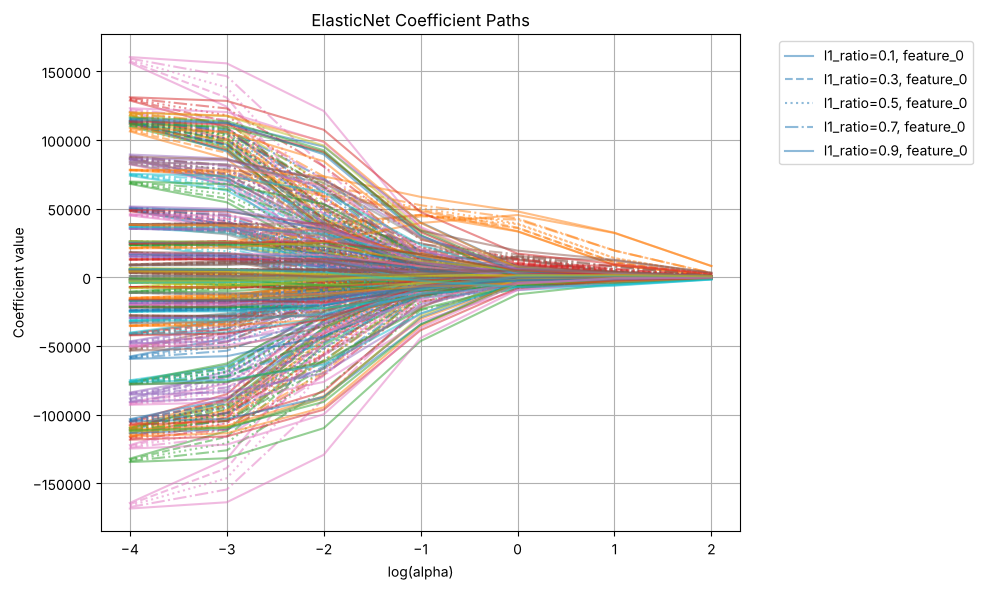

,Model,Mean Squared Error,R-squared
3,ElasticNet Regression,42616635365.79,0.14
0,Ridge Regression,45341091794.40,0.09
1,Lasso Regression,46377111017.93,0.07
2,Linear Regression,46550591070.53,0.06


In [ ]:
# Load libraries
from sklearn.linear_model import ElasticNet

# Create a range of alphas to test
alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9]

# Store coefficients for plotting
coef_paths = []
labels = []

# Create and fit ElasticNet models with different parameters
plt.figure(figsize=(10, 6))

for l1_ratio in l1_ratios:
    coefs = []
    for alpha in alphas:
        # Create and fit ElasticNet model with increased max_iter and tol
        elastic_model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=123,
                                 max_iter=10000, tol=1e-4)
        elastic_model.fit(X_train, y_train)
        coefs.append(elastic_model.coef_)

    # Convert coefficients to array and store
    coef_paths.append(np.array(coefs))

    # Plot coefficient paths
    for feature_idx in range(X_train.shape[1]):
        plt.plot(np.log10(alphas),
                np.array(coefs)[:, feature_idx],
                label=f'l1_ratio={l1_ratio}, feature_{feature_idx}' if feature_idx == 0 else "",
                alpha=0.5,
                linestyle=['solid', 'dashed', 'dotted', 'dashdot', '-'][l1_ratios.index(l1_ratio)])

plt.xlabel('log(alpha)')
plt.ylabel('Coefficient value')
plt.title('ElasticNet Coefficient Paths')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

# Create a model with balanced l1_ratio and moderate alpha
elastic_model = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=123,
                          max_iter=10000, tol=1e-4)
elastic_model.fit(X_train, y_train)

# Calculate metrics
elastic_pred = elastic_model.predict(X_test)
elastic_mse = mean_squared_error(y_test, elastic_pred)
elastic_r2 = r2_score(y_test, elastic_pred)

# Add ElasticNet results to metrics DataFrame
new_row = pd.DataFrame({
    'Model': ['ElasticNet Regression'],
    'Mean Squared Error': [elastic_mse],
    'R-squared': [elastic_r2]
})

# Remove any existing ElasticNet entries before concatenating
metrics_df = metrics_df[~metrics_df['Model'].str.contains('ElasticNet')]

# Convert string values back to float for sorting
metrics_df['Mean Squared Error'] = metrics_df['Mean Squared Error'].astype(float)
metrics_df['R-squared'] = metrics_df['R-squared'].astype(float)

metrics_df = pd.concat([metrics_df, new_row], ignore_index=True)

# Sort the metrics DataFrame by Mean Squared Error
metrics_df = metrics_df.sort_values('Mean Squared Error', ascending=True)

# Format the numeric columns for display
metrics_df['Mean Squared Error'] = metrics_df['Mean Squared Error'].map('{:.2f}'.format)
metrics_df['R-squared'] = metrics_df['R-squared'].map('{:.2f}'.format)

# Display updated metrics
display(metrics_df)

**Interpretasi.**
- **Coefficient path**: di sisi kiri ($\alpha$ kecil) koefisien besar dan menyebar; ke kanan ($\alpha$ besar) semuanya menyusut ke nol. Garis dengan `l1_ratio` berbeda menunjukkan bahwa makin besar porsi L1, makin cepat koefisien mencapai nol.
- Dengan `alpha=1.0, l1_ratio=0.5`, ElasticNet memberi $R^2$ ≈ 0,14 — **terbaik** di antara keempat model, dan mendekati batas atas ≈0,21 yang sudah kita hitung. Di sini, penalti ElasticNet (dengan skala $1/2n$ pada galat) jauh lebih kuat dibanding Ridge `alpha=1` dan Lasso `alpha=10`, sehingga model lebih banyak mengabaikan noise. Efek pengelompokan L2 juga membuat bobot tersebar ke fitur yang berpasangan (misal `feature_21` dan salinannya `feature_71`) alih-alih saling meniadakan.

## Resep 4 — Regresi Polinomial dan Spline

### Teori
Model "linear" sebenarnya berarti **linear dalam parameter**, bukan dalam fitur. Kita bisa mentransformasi fitur dengan fungsi basis $\phi(x)$ lalu tetap memakai OLS:
$$y = \sum_{m=0}^{M} \beta_m\,\phi_m(x) + \varepsilon$$

**Regresi polinomial:** $\phi_m(x) = x^m$, sehingga $y = \beta_0 + \beta_1x + \beta_2x^2 + \dots + \beta_dx^d$.
- Derajat rendah → underfitting; derajat tinggi → overfitting dan perilaku liar di tepi data (**fenomena Runge**).
- Polinomial bersifat **global**: mengubah satu koefisien memengaruhi kurva di seluruh domain.

**Spline (B-spline):** domain dibagi oleh $K$ titik *knot*, dan pada setiap segmen dipasang polinomial berderajat rendah (biasanya kubik, derajat 3). Polinomial antar-segmen disambung secara mulus — untuk spline kubik, nilai, turunan pertama, dan turunan kedua kontinu di setiap knot. Basis B-spline bersifat **lokal** (setiap fungsi basis hanya tidak-nol pada beberapa segmen), sehingga spline jauh lebih fleksibel dan stabil daripada polinomial derajat tinggi. Jumlah fungsi basis = `n_knots + degree − 1`.

### Persiapan — data non-linear
Target dibangkitkan dari $y = 2x + 27\sin(x/8) + \varepsilon$ dengan $\varepsilon \sim \mathcal N(0, 4^2)$ dan $x \in [-50, 50]$.

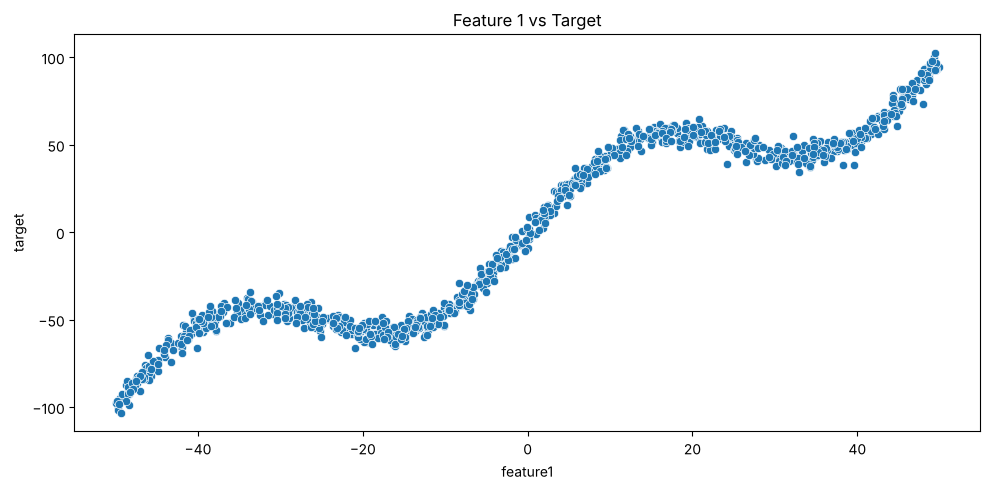

In [ ]:
# Load libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create synthetic dataset with non-linear relationships
np.random.seed(123)
n_samples = 1000
X = np.random.uniform(-50, 50, (n_samples, 1))

# Create target with non-linear components:
y = (2 * X[:, 0]  # linear component
     + 27 * np.sin(X[:, 0] / 8)
     + np.random.normal(0, 4, n_samples))  # noise

# Create DataFrame
data = pd.DataFrame(X, columns=['feature1'])
data['target'] = y

# Create plot
plt.figure(figsize=(10, 5))
sns.scatterplot(data=data, x='feature1', y='target')
plt.title('Feature 1 vs Target')
plt.tight_layout()
plt.show()

### Regresi polinomial derajat 1–5


Model Performance Metrics:
 Degree        MSE       R2
      1 317.005037 0.891135
      2 316.818454 0.891199
      3 268.477397 0.907800
      4 268.230101 0.907885
      5 811.070884 0.721464


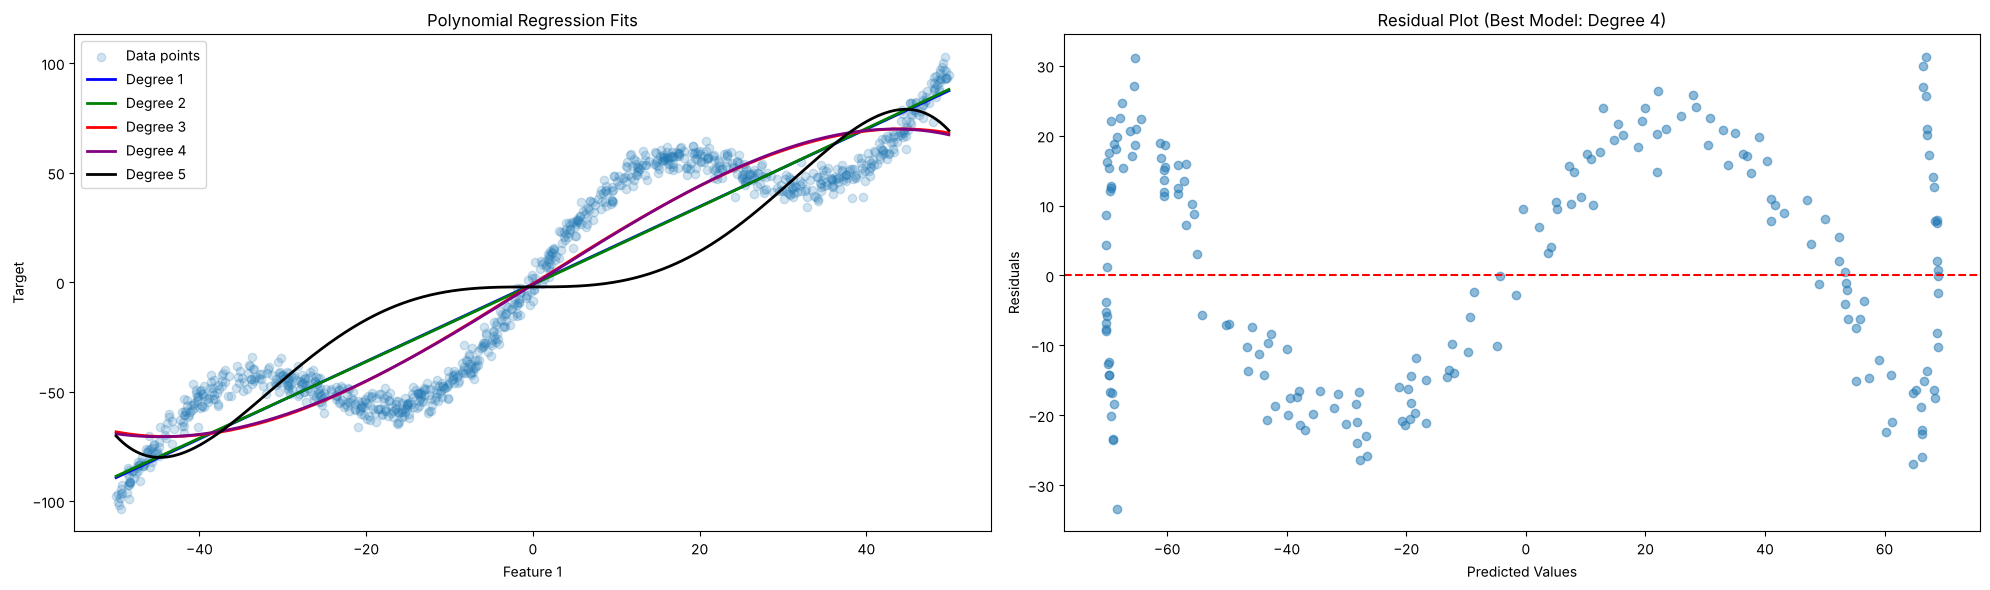

In [ ]:
# Load libraries
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import matplotlib.pyplot as plt

# Use the synthetic dataset created above
X = data[['feature1']]
y = data['target']

# Create a list of polynomial degrees to try
degrees = [1, 2, 3, 4, 5]
results = []

# Try different polynomial degrees
for degree in degrees:
    # Transform features to polynomial features
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X)

    # Split into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=123)

    # Create and fit Linear Regression model on polynomial features
    poly_model = LinearRegression()
    poly_model.fit(X_train, y_train)

    # Make predictions
    y_pred = poly_model.predict(X_test)

    # Calculate metrics
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # Store results
    results.append({
        'Degree': degree,
        'MSE': mse,
        'R2': r2
    })

# Create DataFrame of results
results_df = pd.DataFrame(results)
print("\nModel Performance Metrics:")
print(results_df.to_string(index=False))

# Create visualization of different polynomial fits
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6))

# Plot data and polynomial fits
ax1.scatter(X['feature1'], y, alpha=0.2, label='Data points')

# Generate points for smooth curve plotting
X_plot = np.linspace(X['feature1'].min(), X['feature1'].max(), 1000).reshape(-1, 1)

colors = ['blue', 'green', 'red', 'purple', 'black']
for degree, color in zip(degrees, colors):
    poly = PolynomialFeatures(degree=degree)
    X_plot_poly = poly.fit_transform(X_plot)

    model = LinearRegression()
    model.fit(poly.fit_transform(X), y)
    y_plot = model.predict(X_plot_poly)

    ax1.plot(X_plot, y_plot, label=f'Degree {degree}', color=color, linewidth=2)

ax1.set_xlabel('Feature 1')
ax1.set_ylabel('Target')
ax1.set_title('Polynomial Regression Fits')
ax1.legend(loc='upper left')

# Plot residuals for best performing model (based on R2)
best_degree = results_df.loc[results_df['R2'].idxmax(), 'Degree']
best_poly = PolynomialFeatures(degree=best_degree)
X_poly_best = best_poly.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_poly_best, y, test_size=0.2, random_state=123)

best_model = LinearRegression()
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
residuals = y_test - y_pred

ax2.scatter(y_pred, residuals, alpha=0.5)
ax2.axhline(y=0, color='r', linestyle='--')
ax2.set_xlabel('Predicted Values')
ax2.set_ylabel('Residuals')
ax2.set_title(f'Residual Plot (Best Model: Degree {best_degree})')

plt.tight_layout()
plt.show()

**Interpretasi.**
- Derajat 1–2 memberi $R^2$ ≈ 0,891 — tren linear $2x$ sudah menjelaskan sebagian besar variasi. Menambah suku $x^2$ hampir tidak membantu karena fungsi sebenarnya ($2x + 27\sin(x/8)$) adalah fungsi **ganjil**, sehingga suku berderajat genap tidak berguna.
- Derajat 3–4 sedikit lebih baik ($R^2$ ≈ 0,908) karena $x^3$ bisa meniru satu "lengkungan" sinus.
- Derajat 5 justru **memburuk tajam** ($R^2$ ≈ 0,72). Penyebabnya numerik: $x$ bernilai hingga ±50 sehingga $x^5$ mencapai ~$3\times10^8$. Fitur dengan skala yang sangat berbeda membuat $\mathbf X^\top\mathbf X$ sangat *ill-conditioned*, dan solusi OLS menjadi tidak akurat. Menstandardisasi $x$ sebelum `PolynomialFeatures` akan memperbaikinya.
- Polinomial derajat rendah tetap **tidak bisa** mengikuti gelombang sinus dengan periode $16\pi \approx 50$ di rentang $[-50, 50]$ — dibutuhkan basis yang lebih fleksibel. Plot residual pada model terbaik masih memperlihatkan pola bergelombang (bukan acak), tanda masih ada struktur yang belum tertangkap.

### Interpolasi spline dengan jumlah knot berbeda

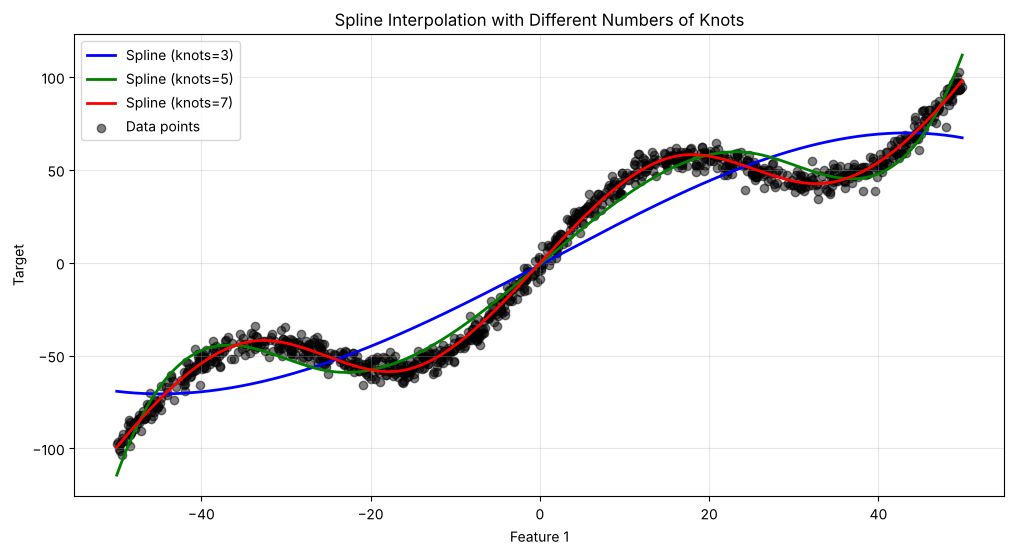

,Number of Knots,MSE,R-squared
0,3,274.267019,0.904652
1,5,55.347798,0.980759
2,7,15.502097,0.994611


In [ ]:
# Load libraries
from sklearn.preprocessing import SplineTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

# Create a spline transformer with different degrees of freedom
n_knots = [3, 5, 7]  # Different numbers of knots to try
plt.figure(figsize=(12, 6))

# Create lists to store metrics
mse_scores = []
r2_scores = []

for n_knot, color in zip(n_knots, colors[:len(n_knots)]):
    # Create and fit spline transformer
    spline = SplineTransformer(n_knots=n_knot, degree=3)
    model = make_pipeline(spline, LinearRegression())
    model.fit(X, y)

    # Generate predictions
    y_pred = model.predict(X_plot)
    y_pred_train = model.predict(X)

    # Calculate metrics
    mse = mean_squared_error(y, y_pred_train)
    r2 = r2_score(y, y_pred_train)
    mse_scores.append(mse)
    r2_scores.append(r2)

    # Plot the results
    plt.plot(X_plot, y_pred,
             label=f'Spline (knots={n_knot})',
             color=color,
             linewidth=2)

# Plot original data points
plt.scatter(X, y, color='black', alpha=0.5, label='Data points')
plt.xlabel('Feature 1')
plt.ylabel('Target')
plt.title('Spline Interpolation with Different Numbers of Knots')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Create and display metrics DataFrame
metrics_df = pd.DataFrame({
    'Number of Knots': n_knots,
    'MSE': mse_scores,
    'R-squared': r2_scores
})
display(metrics_df)

**Interpretasi.** Spline kubik jauh mengungguli polinomial: 3 knot ($R^2$ ≈ 0,905, setara polinomial derajat 3–4), 5 knot (≈ 0,981), dan 7 knot (≈ **0,995**, MSE ≈ 15,5 — mendekati varians noise sebenarnya $4^2 = 16$). Dengan 7 knot, setiap segmen cukup pendek untuk mengikuti satu bagian gelombang sinus. MSE yang mendekati varians noise berarti model menangkap hampir seluruh sinyal dan sisanya adalah noise yang memang tak bisa diprediksi.

Catatan metodologis: metrik di tabel ini dihitung pada **data latih** (kode buku memakai `model.fit(X, y)` lalu mengevaluasi pada `X` yang sama). Untuk memilih jumlah knot secara jujur, gunakan data uji atau cross-validation, karena knot yang terlalu banyak akan mulai mengikuti noise.

## Latihan Praktik

### Latihan 1 — Ridge Regression
Data: $y = 0{,}5x^2 + x + \varepsilon$ pada $x \in [-3, 3]$ (hubungan kuadratik), dimodelkan dengan Ridge **linear**.

Training Metrics:
MSE: 1.9780
R²: 0.6575

Test Metrics:
MSE: 2.5628
R²: -0.0360


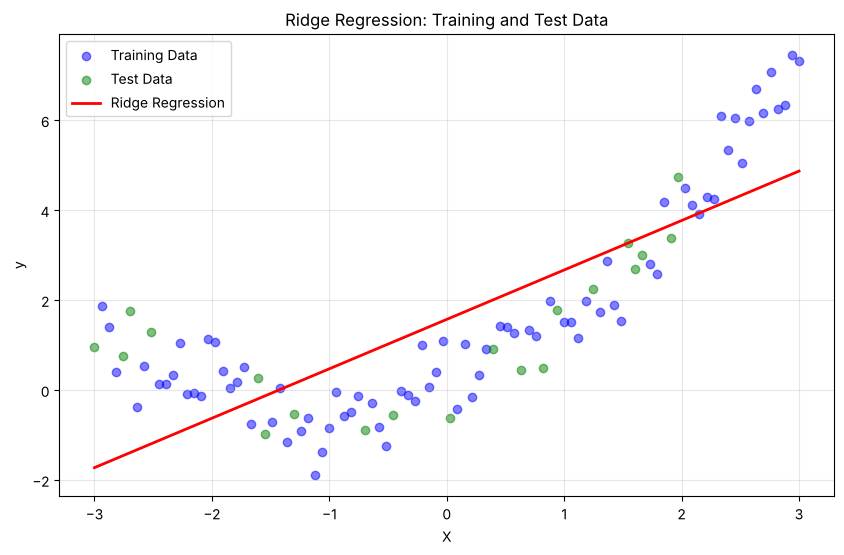

In [ ]:
# Load libraries
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Generate synthetic dataset with some noise
np.random.seed(123)
X = np.linspace(-3, 3, 100).reshape(-1, 1)
y = 0.5 * X.ravel()**2 + X.ravel() + np.random.normal(0, 0.5, 100)

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

# Create and fit Ridge regression model
ridge = Ridge(alpha=1.0)  # alpha is the regularization strength
ridge.fit(X_train, y_train)

# Make predictions
y_pred_train = ridge.predict(X_train)
y_pred_test = ridge.predict(X_test)

# Calculate metrics
mse_train = mean_squared_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

# Print metrics
print("Training Metrics:")
print(f"MSE: {mse_train:.4f}")
print(f"R²: {r2_train:.4f}")
print("\nTest Metrics:")
print(f"MSE: {mse_test:.4f}")
print(f"R²: {r2_test:.4f}")

# Visualize results
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Training Data')
plt.scatter(X_test, y_test, color='green', alpha=0.5, label='Test Data')

# Sort X values for smooth line plot
X_plot = np.sort(X, axis=0)
y_plot = ridge.predict(X_plot)
plt.plot(X_plot, y_plot, color='red', linewidth=2, label='Ridge Regression')

plt.xlabel('X')
plt.ylabel('y')
plt.title('Ridge Regression: Training and Test Data')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Interpretasi.** Ridge **linear** dipasang pada data yang **kuadratik**: $R^2$ latih ≈ 0,66, sedangkan $R^2$ uji ≈ −0,04 (lebih buruk daripada sekadar memprediksi rata-rata). Ini contoh **underfitting** — masalahnya bukan regularisasi, tetapi bentuk model yang salah (garis lurus untuk parabola). Regularisasi tidak bisa memperbaiki bias model. Solusinya adalah menambahkan fitur $x^2$ (misalnya `make_pipeline(PolynomialFeatures(2), Ridge())`). $R^2$ negatif juga bisa terjadi karena data uji hanya 20 titik sehingga sangat sensitif terhadap titik mana yang terpilih.

### Latihan 2 — Lasso Regression
Data: $y = 4 + 3x + \varepsilon$ dengan $\varepsilon\sim\mathcal N(0, 0{,}5^2)$ — hubungan yang memang linear.

Training Metrics:
MSE: 0.2631
R²: 0.8814

Test Metrics:
MSE: 0.4239
R²: 0.8419


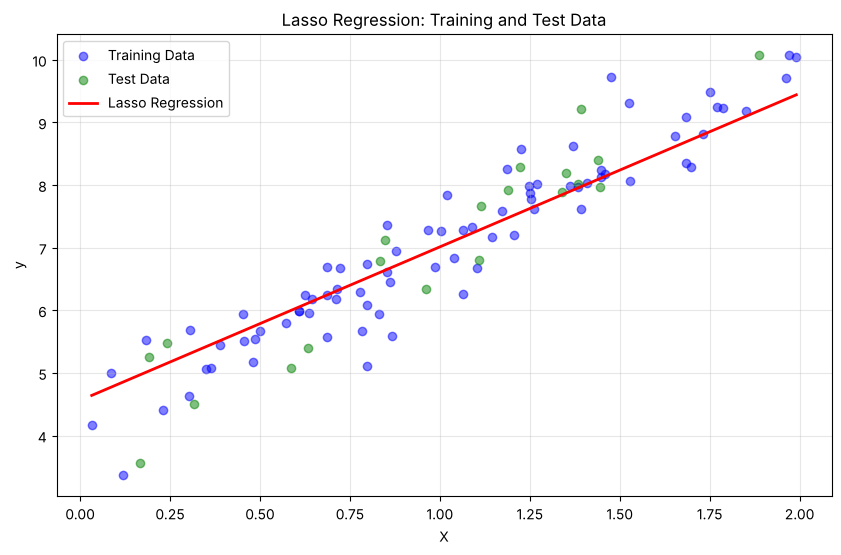

In [ ]:
# Load libraries
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Generate synthetic data
np.random.seed(123)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1) * 0.5

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

# Create and fit Lasso regression model
lasso = Lasso(alpha=0.1)  # alpha is the regularization strength
lasso.fit(X_train, y_train)

# Make predictions
y_pred_train = lasso.predict(X_train)
y_pred_test = lasso.predict(X_test)

# Calculate metrics
mse_train = mean_squared_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

# Print metrics
print("Training Metrics:")
print(f"MSE: {mse_train:.4f}")
print(f"R²: {r2_train:.4f}")
print("\nTest Metrics:")
print(f"MSE: {mse_test:.4f}")
print(f"R²: {r2_test:.4f}")

# Visualize results
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Training Data')
plt.scatter(X_test, y_test, color='green', alpha=0.5, label='Test Data')

# Sort X values for smooth line plot
X_plot = np.sort(X, axis=0)
y_plot = lasso.predict(X_plot)
plt.plot(X_plot, y_plot, color='red', linewidth=2, label='Lasso Regression')

plt.xlabel('X')
plt.ylabel('y')
plt.title('Lasso Regression: Training and Test Data')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
print('Koefisien Lasso: %.4f (nilai sebenarnya 3)' % np.ravel(lasso.coef_)[0])
print('Intersep Lasso : %.4f (nilai sebenarnya 4)' % np.ravel(lasso.intercept_)[0])

Koefisien Lasso: 2.4508 (nilai sebenarnya 3)
Intersep Lasso : 4.5625 (nilai sebenarnya 4)


**Interpretasi.** Model sudah baik ($R^2$ uji ≈ 0,84), tetapi koefisien Lasso ≈ 2,45, sedangkan nilai sebenarnya 3. Ini adalah **bias shrinkage** dari penalti L1: Lasso selalu menarik koefisien ke arah nol (koefisien yang dibuat 0,55 lebih kecil), dan intersep naik untuk mengompensasi. Jika tujuannya interpretasi koefisien yang tidak bias pada data yang memang linear dengan satu fitur, OLS biasa lebih tepat; Lasso berguna ketika ada banyak fitur dan kita ingin seleksi fitur.

### Latihan 3 — ElasticNet Regression
Data: $y = 3x + 2\sin(x) + \varepsilon$ pada $x\in[-10, 10]$ — tren linear yang kuat dengan riak sinus kecil.

Training Metrics:
MSE: 4.6771
R²: 0.9849

Test Metrics:
MSE: 4.0393
R²: 0.9867


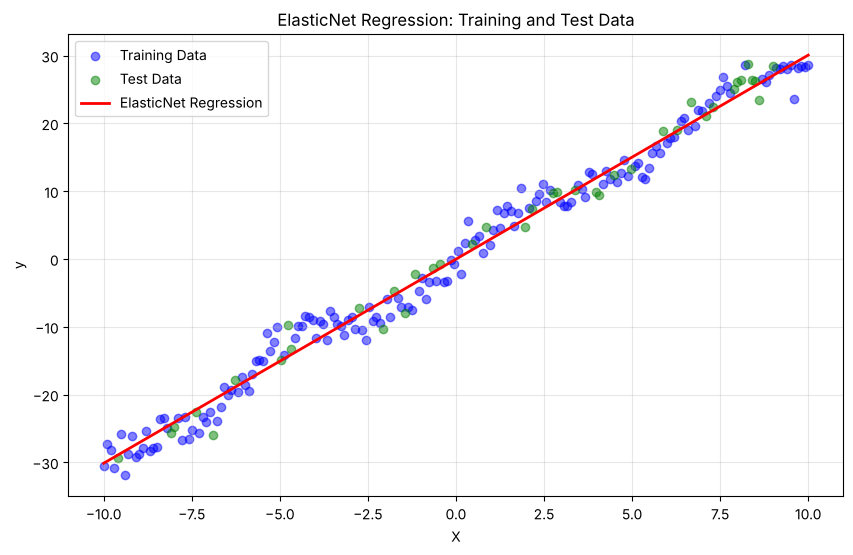

In [ ]:
# Load libraries
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Generate synthetic data
np.random.seed(123)
X = np.linspace(-10, 10, 200).reshape(-1, 1)
y = 3*X + np.sin(X) * 2 + np.random.normal(0, 1.5, X.shape)

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

# Create and fit ElasticNet model
elastic_net = ElasticNet(alpha=0.1, l1_ratio=0.5)  # alpha is regularization strength, l1_ratio balances L1/L2
elastic_net.fit(X_train, y_train)

# Make predictions
y_pred_train = elastic_net.predict(X_train)
y_pred_test = elastic_net.predict(X_test)

# Calculate metrics
mse_train = mean_squared_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

# Print metrics
print("Training Metrics:")
print(f"MSE: {mse_train:.4f}")
print(f"R²: {r2_train:.4f}")
print("\nTest Metrics:")
print(f"MSE: {mse_test:.4f}")
print(f"R²: {r2_test:.4f}")

# Visualize results
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Training Data')
plt.scatter(X_test, y_test, color='green', alpha=0.5, label='Test Data')

# Sort X values for smooth line plot
X_plot = np.sort(X, axis=0)
y_plot = elastic_net.predict(X_plot)
plt.plot(X_plot, y_plot, color='red', linewidth=2, label='ElasticNet Regression')

plt.xlabel('X')
plt.ylabel('y')
plt.title('ElasticNet Regression: Training and Test Data')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Interpretasi.** ElasticNet mencapai $R^2$ ≈ 0,985 (latih) dan ≈ 0,987 (uji): tren linear $3x$ menjelaskan hampir semua variasi karena rentang $x$ lebar ($[-10, 10]$), sedangkan komponen $2\sin(x)$ dan noise relatif kecil. Skor uji yang sedikit **lebih tinggi** daripada skor latih tidak aneh untuk data kecil — itu hanya variasi acak dari pembagian data, dan menandakan tidak ada overfitting. Riak sinus tidak tertangkap oleh model linear; sisa MSE ≈ 4 sebanding dengan varians sinus ($2^2/2 = 2$) ditambah varians noise ($1{,}5^2 = 2{,}25$).

## Kesimpulan Bab 5

| Model | Penalti | Koefisien nol? | Kapan dipakai |
|---|---|---|---|
| OLS (`LinearRegression`) | – | Tidak | fitur sedikit, tidak multikolinear |
| `Ridge` | $\alpha\lVert\beta\rVert_2^2$ | Tidak (hanya mengecil) | banyak fitur berkorelasi, semua dianggap relevan |
| `Lasso` | $\alpha\lVert\beta\rVert_1$ | **Ya** → seleksi fitur | diduga hanya sedikit fitur yang relevan |
| `ElasticNet` | kombinasi L1 + L2 | Ya | fitur berkorelasi berkelompok dan ingin sparsity |

- Multikolinearitas membuat koefisien OLS tidak stabil; regularisasi menstabilkannya dengan sedikit menambah bias (bias–variance trade-off).
- $\alpha$ dan `l1_ratio` adalah hyperparameter yang sebaiknya dipilih dengan cross-validation (`RidgeCV`, `LassoCV`, `ElasticNetCV`).
- Model linear dapat menangkap non-linearitas melalui fungsi basis: polinomial (global) atau spline (lokal, lebih stabil).
- Selalu standardisasi fitur sebelum regularisasi agar penalti adil untuk semua koefisien.